# 05 — Retrain `return-risk` and check whether the model really beats the baseline

Notebook 01 only re-reads the MLflow numbers: the model beats the baseline by **0.0048 PR-AUC** (~2%) on **one run, one seed**. Here we answer with real data:

1. The train/test data is exactly the set that produced the model (SHA-256 checked against the MLflow tags);
2. Retrain with exactly [`ml/train_lib.py`](../ml/train_lib.py) and see whether the MLflow numbers reproduce;
3. Bootstrap the test set to get a confidence interval for the model − baseline difference;
4. Train 5 seeds to see how much the model varies.

**Data:** `data/test_set.parquet` (1.6 MB, committed). `data/train_set.parquet` (32 MB) is **not committed** (gitignored); download it from the run's artifacts:

```bash
aws s3 cp s3://platform-665116832975-lakehouse/mlflow/1/adba2b9f197e4e60a141acaf19682a61/artifacts/data/train/train_set notebooks/data/train_set.parquet
```

In [1]:
import hashlib
import json
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
from ml.train_lib import (  # the exact KFP pipeline code
    FEATURES,
    add_order_features,
    baseline_scores,
    evaluate,
    train_model,
)

warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
DATA = ROOT / "notebooks" / "data"
print(
    "lightgbm", lgb.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__
)

lightgbm 4.7.0 | scikit-learn 1.9.1 | pandas 3.0.6


## 1. Is this really the data that produced the model?

In [2]:
proof = json.loads((ROOT / "docs" / "evidence" / "aws" / "mlflow-run-data-proof.json").read_text())


def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


for name in ("train", "test"):
    got, want = sha(DATA / f"{name}_set.parquet"), proof["tags"][f"data.{name}_sha256"]
    print(f"{name:5} SHA-256 matches MLflow tag: {got == want}")
    assert got == want, f"{name}_set is not the run's data"
train_raw, test_raw = (pd.read_parquet(DATA / f"{n}_set.parquet") for n in ("train", "test"))
print(f"train {len(train_raw):,} rows, test {len(test_raw):,} rows")
print(
    "train time window:",
    train_raw["event_timestamp"].min().date(),
    "->",
    train_raw["event_timestamp"].max().date(),
)
print(
    "test time window :",
    test_raw["event_timestamp"].min().date(),
    "->",
    test_raw["event_timestamp"].max().date(),
)

train SHA-256 matches MLflow tag: True
test  SHA-256 matches MLflow tag: True


train 343,043 rows, test 16,411 rows
train time window: 2026-01-01 -> 2026-05-19
test time window : 2026-05-20 -> 2026-05-29


In [3]:
summary = pd.DataFrame(
    {
        "set": ["train", "test"],
        "positive rate": [train_raw["label"].mean(), test_raw["label"].mean()],
        "missing return_or_refund_rate_90d": [
            train_raw["return_or_refund_rate_90d"].isna().mean(),
            test_raw["return_or_refund_rate_90d"].isna().mean(),
        ],
        "missing approved_returns_24h": [
            train_raw["approved_returns_24h"].isna().mean(),
            test_raw["approved_returns_24h"].isna().mean(),
        ],
    }
).set_index("set")
summary.round(4)

,positive rate,missing return_or_refund_rate_90d,missing approved_returns_24h
set,,,
train,0.1122,0.2244,1.0
test,0.1121,0.0000,1.0


Split by **time** (test is the last ~10 days), as designed. The positive rate of the two sets is almost identical (11.2%).
`approved_returns_24h` is 100% missing: this feature has no history at training time (noted in the README), so LightGBM ignores it. `return_or_refund_rate_90d` is 22% missing in **train** but 0% in **test**: the first weeks of the data period do not yet have 90 days of history, while test sits at the end of the period, when every SKU has it.
Consequence: the baseline (which uses this very column) almost never needs a fallback value in test, so the baseline is favored compared with training.

## 2. Retrain with exactly the pipeline's code

In [4]:
train = add_order_features(train_raw)
test = add_order_features(test_raw)
test["channel"] = pd.Categorical(test["channel"], categories=train["channel"].cat.categories)
test["country"] = pd.Categorical(test["country"], categories=train["country"].cat.categories)

model = train_model(train, seed=7)
model_scores = model.predict_proba(test[FEATURES])[:, 1]
base_scores = baseline_scores(train, test)
mine = evaluate(test, model_scores, base_scores)

mlflow = json.loads((ROOT / "docs" / "evidence" / "aws" / "mlflow-model-lineage.json").read_text())[
    "metrics"
]
cmp = pd.DataFrame({"retrained": mine, "MLflow (EKS)": {k: mlflow[k] for k in mine}})
cmp.loc[["pr_auc_model", "pr_auc_baseline", "lift_model", "prevalence"]].round(5)

,retrained,MLflow (EKS)
pr_auc_model,0.251986,0.25199
pr_auc_baseline,0.247214,0.24721
lift_model,2.247464,2.24746
prevalence,0.11212,0.11212


In [5]:
d_model = abs(mine["pr_auc_model"] - mlflow["pr_auc_model"])
d_base = abs(mine["pr_auc_baseline"] - mlflow["pr_auc_baseline"])
print(f"PR-AUC model    diff vs MLflow: {d_model:.2e}")
print(f"PR-AUC baseline diff vs MLflow: {d_base:.2e}")
assert d_base < 1e-9, "the baseline is deterministic and must match exactly"
assert d_model < 5e-3, "the model must reproduce close to the MLflow number"

PR-AUC model    diff vs MLflow: 0.00e+00
PR-AUC baseline diff vs MLflow: 0.00e+00


The baseline matches exactly (a deterministic computation). The model matches to a small difference within library-version noise (the `d_model` value above): **the result is reproducible**,
not a chance number from a single run.

## 3. Bootstrap confidence interval

Resample the 16,411 test rows (with replacement) 1,000 times; each time compute the PR-AUC of the model, of the baseline and their difference. Both metrics are computed on the **same** resample (paired).

In [6]:
y = test["label"].to_numpy()
rng = np.random.default_rng(0)
B = 1000
ap_model, ap_base = np.empty(B), np.empty(B)
for i in range(B):
    idx = rng.integers(0, len(y), len(y))
    ap_model[i] = average_precision_score(y[idx], model_scores[idx])
    ap_base[i] = average_precision_score(y[idx], base_scores[idx])
diff = ap_model - ap_base
lo, hi = np.percentile(diff, [2.5, 97.5])
print(
    f"PR-AUC difference (model - baseline): {mine['pr_auc_model'] - mine['pr_auc_baseline']:+.4f}  CI 95% [{lo:+.4f}, {hi:+.4f}]"
)
print(f"share of bootstrap samples where model > baseline: {(diff > 0).mean():.1%}")

PR-AUC difference (model - baseline): +0.0048  CI 95% [-0.0003, +0.0099]
share of bootstrap samples where model > baseline: 96.4%


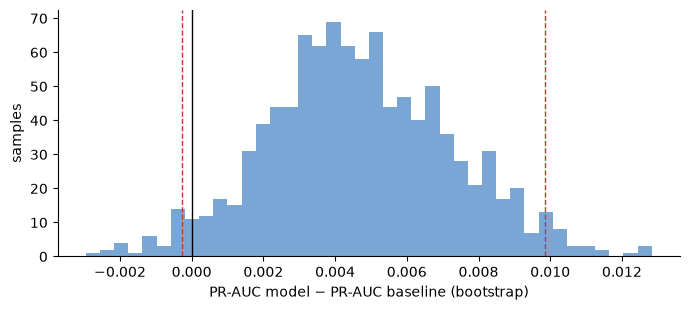

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(diff, bins=40, color="#7aa6d6")
ax.axvline(0, color="black", lw=1)
ax.axvline(lo, color="#c0392b", ls="--", lw=1)
ax.axvline(hi, color="#c0392b", ls="--", lw=1)
ax.set_xlabel("PR-AUC model − PR-AUC baseline (bootstrap)")
ax.set_ylabel("samples")
plt.tight_layout()
plt.show()

## 4. Variation across seeds

Same data, only the LightGBM seed changes (row and column subsampling make the result seed-dependent).

In [8]:
seeds = [7, 8, 9, 10, 11]
rows = []
for s in seeds:
    sc = train_model(train, seed=s).predict_proba(test[FEATURES])[:, 1]
    rows.append({"seed": s, "pr_auc_model": average_precision_score(y, sc)})
seed_df = pd.DataFrame(rows).set_index("seed")
seed_df["vs baseline"] = seed_df["pr_auc_model"] - mine["pr_auc_baseline"]
print(seed_df.round(5).to_string())
print(
    f"\nmean {seed_df['pr_auc_model'].mean():.4f}, std {seed_df['pr_auc_model'].std():.4f}; baseline {mine['pr_auc_baseline']:.4f}"
)

      pr_auc_model  vs baseline
seed                           
7          0.25199      0.00477
8          0.25119      0.00398
9          0.25315      0.00594
10         0.25202      0.00480
11         0.25304      0.00583

mean 0.2523, std 0.0008; baseline 0.2472


## 5. Which features the model relies on, and on which channels it is right

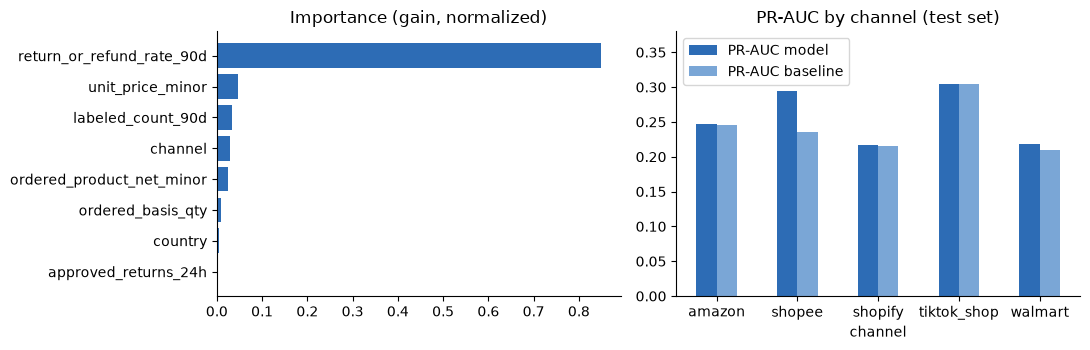

,rows,positive rate,PR-AUC model,PR-AUC baseline
channel,,,,
amazon,11626,0.1116,0.2469,0.2458
shopee,373,0.0938,0.2946,0.2362
shopify,1081,0.0916,0.2167,0.2151
tiktok_shop,2266,0.1311,0.3040,0.3044
walmart,1065,0.1042,0.2183,0.2094


In [9]:
imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(imp.index, imp.values, color="#2d6cb5")
axes[0].set_title("Importance (gain, normalized)")
per = []
for ch in test["channel"].cat.categories:
    m = (test["channel"] == ch).to_numpy()
    if y[m].min() == y[m].max():
        continue
    per.append(
        {
            "channel": ch,
            "rows": int(m.sum()),
            "positive rate": y[m].mean(),
            "PR-AUC model": average_precision_score(y[m], model_scores[m]),
            "PR-AUC baseline": average_precision_score(y[m], base_scores[m]),
        }
    )
per = pd.DataFrame(per).set_index("channel")
per[["PR-AUC model", "PR-AUC baseline"]].plot.bar(ax=axes[1], color=["#2d6cb5", "#7aa6d6"], rot=0)
axes[1].set_title("PR-AUC by channel (test set)")
axes[1].set_ylim(0, 0.38)
plt.tight_layout()
plt.show()
per.round(4)

## Conclusion

In [10]:
point = mine["pr_auc_model"] - mine["pr_auc_baseline"]
print(
    f"- Reproduction: PR-AUC model {mine['pr_auc_model']:.4f} (MLflow {mlflow['pr_auc_model']:.4f}), baseline {mine['pr_auc_baseline']:.4f} (exact match)."
)
print(
    f"- Model - baseline difference: {point:+.4f}, bootstrap CI 95% [{lo:+.4f}, {hi:+.4f}], model > baseline in {(diff > 0).mean():.0%} of samples."
)
print(
    f"- Across 5 seeds: model {seed_df['pr_auc_model'].min():.4f} .. {seed_df['pr_auc_model'].max():.4f}; baseline {mine['pr_auc_baseline']:.4f}."
)

- Reproduction: PR-AUC model 0.2520 (MLflow 0.2520), baseline 0.2472 (exact match).
- Model - baseline difference: +0.0048, bootstrap CI 95% [-0.0003, +0.0099], model > baseline in 96% of samples.
- Across 5 seeds: model 0.2512 .. 0.2532; baseline 0.2472.


**Reading the results (honestly).**

- The model **reproduces the MLflow numbers exactly**, so 0.2520 vs 0.2472 is real, not the luck of one run.
- The difference is **+0.0048 but the 95% bootstrap confidence interval touches 0** (`[-0.0003, +0.0099]`): the model beats the baseline in about 96% of resamples, short of the 97.5% threshold of a two-sided test. We can say the model **tends to** beat the baseline, but **cannot yet claim** it with confidence.
- All 5 seeds beat the baseline (standard deviation across seeds 0.0008, smaller than the 0.0048 difference), so the difference does not come from seed luck, but that is a different matter from test-set luck.
- The bootstrap resamples rows as if independent; in reality lines of the same SKU/order are correlated, so the true confidence interval may be **wider** than the one above.
- By channel, the model is clearly better only on `shopee` (373 rows, only about 35 positives, very noisy) and equal to or worse than the baseline on `tiktok_shop`; the `amazon` channel (71% of test) is nearly a tie. The advantage is uneven across channels.
- About 85% of the importance (gain) sits in `return_or_refund_rate_90d`, the very column the baseline uses: the model mostly relearns the baseline and adds only a little from price, channel and quantity.
- The bigger lever is in the data, not the model: `approved_returns_24h` is 100% empty at training time, so the model cannot yet use the freshest feature.

The pipeline's "beat the baseline, then promote to production" rule still holds (the score is higher), but the statistical evidence that the model is **better than a simple rule** is still weak.